# CIFAR-10 with only 500 images (distribution shift)

## Setup

In [27]:
import random, time, copy
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

In [28]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
EPOCHS = 60
SEEDS = [0, 1, 2]
class_names = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
print(device)

cuda


In [29]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [30]:
train_data = torchvision.datasets.CIFAR10('./data', train=True, download=True)
test_data = torchvision.datasets.CIFAR10('./data', train=False, download=True)

In [31]:
def to_tensors(dataset):
    images = torch.tensor(dataset.data).permute(0, 3, 1, 2).float() / 255
    labels = torch.tensor(dataset.targets)
    return images, labels

all_images, all_labels = to_tensors(train_data)
clean_images, clean_labels = to_tensors(test_data)
print(all_images.shape, clean_images.shape)

torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


In [32]:
# pick 50 images from each class: 40 for training, 10 for validation
set_seed(0)
train_idx = []
val_idx = []
for c in range(10):
    idx = (all_labels == c).nonzero().flatten().tolist()
    idx = random.sample(idx, 50)
    train_idx += idx[:40]
    val_idx += idx[40:]

In [33]:
train_images, train_labels = all_images[train_idx], all_labels[train_idx]
val_images, val_labels = all_images[val_idx], all_labels[val_idx]
print('train:', train_images.shape, ' val:', val_images.shape)

train: torch.Size([400, 3, 32, 32])  val: torch.Size([100, 3, 32, 32])


### Making the shifted test set

In [34]:
def hidden_corruption(img):
    # random grayscale or channel swap
    if random.random() < 0.5:
        gray = img.mean(0, keepdim=True)
        return gray.repeat(3, 1, 1)
    return img[[2, 1, 0]]

In [35]:
def make_shifted(img):
    img = TF.rotate(img, random.uniform(-25, 25))
    img = TF.adjust_brightness(img, random.uniform(0.5, 1.5))
    img = TF.adjust_contrast(img, random.uniform(0.5, 1.5))
    img = TF.gaussian_blur(img, 3)
    img = img + 0.05 * torch.randn_like(img)
    # black box, at most 25% of the image
    h = random.randint(8, 16)
    w = random.randint(8, 16)
    top = random.randint(0, 32 - h)
    left = random.randint(0, 32 - w)
    img[:, top:top + h, left:left + w] = 0
    img = hidden_corruption(img)
    return img.clamp(0, 1)

In [36]:
random.seed(123)
torch.manual_seed(123)
shifted_images = torch.stack([make_shifted(img) for img in clean_images])
shifted_labels = clean_labels.clone()

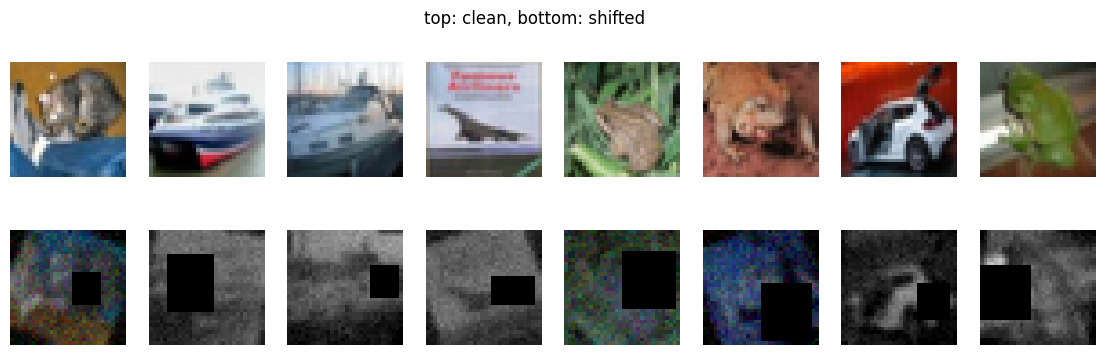

In [37]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    axes[0, i].imshow(clean_images[i].permute(1, 2, 0))
    axes[1, i].imshow(shifted_images[i].permute(1, 2, 0))
    axes[0, i].axis('off')
    axes[1, i].axis('off')
fig.suptitle('top: clean, bottom: shifted')
plt.show()

In [38]:
random.seed(55)
torch.manual_seed(55)
val_shifted = torch.stack([make_shifted(img) for img in val_images])
val_images = torch.cat([val_images, val_shifted])
val_labels = torch.cat([val_labels, val_labels])
print('validation set:', val_images.shape)

validation set: torch.Size([200, 3, 32, 32])




An Inception block has 4 branches that run in parallel and are joined like 1x1 conv, 1x1 then 3x3, 1x1 then 5x5, and max-pool then 1x1. The 1x1 convs reduce channels so there are fewer parameters.
Network: conv, pool, Inception, pool, Inception, pool, avg-pool, fully connected, Dropout, output layer.

In [39]:
def conv_block(in_ch, out_ch, k):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, k, padding=k // 2, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU())

In [40]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, c1, c3, c5, cpool):
        super().__init__()
        self.branch1 = conv_block(in_ch, c1, 1)
        self.branch3 = nn.Sequential(conv_block(in_ch, c3 // 2, 1), conv_block(c3 // 2, c3, 3))
        self.branch5 = nn.Sequential(conv_block(in_ch, c5 // 2, 1), conv_block(c5 // 2, c5, 5))
        self.branch_pool = nn.Sequential(nn.MaxPool2d(3, 1, 1), conv_block(in_ch, cpool, 1))

    def forward(self, x):
        outs = [self.branch1(x), self.branch3(x), self.branch5(x), self.branch_pool(x)]
        return torch.cat(outs, 1)

In [41]:
class SmallNet(nn.Module):
    def __init__(self, drop=0.5):
        super().__init__()
        # mean and std used to normalize the images
        self.register_buffer('mean', torch.tensor([0.49, 0.48, 0.45]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.25, 0.24, 0.26]).view(1, 3, 1, 1))

        self.first = nn.Sequential(conv_block(3, 32, 3), nn.MaxPool2d(2))  
        self.inception1 = InceptionBlock(32, 16, 24, 8, 8)                  
        self.pool1 = nn.MaxPool2d(2)                                        
        self.inception2 = InceptionBlock(56, 32, 48, 16, 16)                
        self.pool2 = nn.MaxPool2d(2)                                        
        self.avgpool = nn.AdaptiveAvgPool2d(2)                              
        self.fc = nn.Linear(112 * 2 * 2, 128)
        self.dropout = nn.Dropout(drop)
        self.out = nn.Linear(128, 10)

   

In [ ]:
 def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.first(x)
        x = self.pool1(self.inception1(x))
        x = self.pool2(self.inception2(x))
        x = self.avgpool(x).flatten(1)
        x = self.dropout(torch.relu(self.fc(x)))
        return self.out(x)

In [42]:
num_params = sum(p.numel() for p in SmallNet().parameters() if p.requires_grad)
print('trainable parameters:', num_params)
assert num_params <= 1_000_000

trainable parameters: 82842


## Augmentation and training


* Geometric: random crop, horizontal flip, rotation
* Photometric: color jitter, blur, noise, random grayscale, channel swap (matches brightness, contrast, blur, noise and the hidden color corruption)
* Cutout : matches the black box occlusion
* Mixup and label smoothing: extra regularization

In [43]:
def add_noise(img):
    return (img + 0.05 * torch.randn_like(img)).clamp(0, 1)

def random_channel_swap(img):
    if random.random() < 0.2:
        img = img[torch.randperm(3)]
    return img

In [44]:
def get_transforms(geo=False, photo=False, erase=False, vflip=False):
    steps = []
    if geo:
        steps += [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.RandomRotation(25)]
        if vflip:
            steps += [T.RandomVerticalFlip()]
    if photo:
        steps += [T.ColorJitter(0.4, 0.4, 0.4), T.GaussianBlur(3, (0.1, 1.0)),
                  T.Lambda(add_noise), T.RandomGrayscale(0.2), T.Lambda(random_channel_swap)]
    if erase:
        steps += [T.RandomErasing(p=0.5, scale=(0.05, 0.25))]
    if len(steps) == 0:
        return None
    return T.Compose(steps)

In [45]:
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[i]

In [46]:
def get_predictions(model, images):
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(images), 500):
            batch = images[i:i + 500].to(device)
            outputs.append(model(batch).cpu())
    return torch.cat(outputs)



In [ ]:
def accuracy(model, images, labels):
    preds = get_predictions(model, images).argmax(1)
    return (preds == labels).float().mean().item() * 100

In [47]:
def train_one_epoch(model, loader, optimizer, loss_fn, use_mixup):
    model.train()
    total_loss = 0
    correct = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if use_mixup:
            lam = np.random.beta(0.4, 0.4)
            order = torch.randperm(len(images)).to(device)
            images = lam * images + (1 - lam) * images[order]
            outputs = model(images)
            loss = lam * loss_fn(outputs, labels) + (1 - lam) * loss_fn(outputs, labels[order])
        else:
            outputs = model(images)
            loss = loss_fn(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)
        correct += (outputs.argmax(1) == labels).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n * 100

In [48]:
def train_model(seed, geo=False, photo=False, erase=False, vflip=False,
                mixup=False, smoothing=0.0, weight_decay=5e-4, drop=0.5,
                epochs=EPOCHS, patience=20):
    set_seed(seed)
    model = SmallNet(drop).to(device)
    dataset = MyDataset(train_images, train_labels, get_transforms(geo, photo, erase, vflip))
    loader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=smoothing)

    history = {'loss': [], 'train_acc': [], 'val_acc': []}
    best_val = -1
    best_weights = None
    wait = 0

    for epoch in range(epochs):
        loss, train_acc = train_one_epoch(model, loader, optimizer, loss_fn, mixup)
        scheduler.step()
        val_acc = accuracy(model, val_images, val_labels)
        history['loss'].append(loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        # keep the best model on validation, stop early if no improvement
        if val_acc >= best_val:
            best_val = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_weights)
    return {'model': model, 'history': history,
            'train_acc': accuracy(model, train_images, train_labels),
            'val_acc': best_val,
            'clean_acc': accuracy(model, clean_images, clean_labels),
            'shifted_acc': accuracy(model, shifted_images, shifted_labels)}

## Part A: Baseline (no augmentation)

In [49]:
baseline = train_model(seed=0)
history = baseline['history']

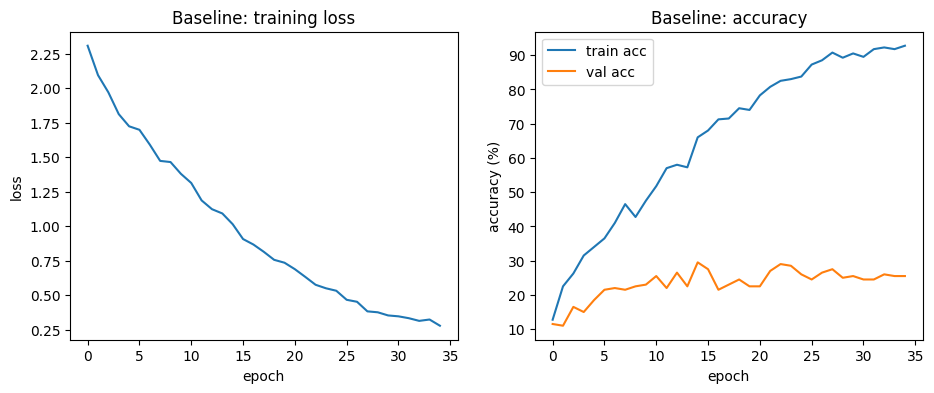

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history['loss'])
axes[0].set_title('Baseline: training loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[1].plot(history['train_acc'], label='train acc')
axes[1].plot(history['val_acc'], label='val acc')
axes[1].set_title('Baseline: accuracy')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy (%)')
axes[1].legend()
plt.show()

In [51]:
print('train accuracy   :', round(baseline['train_acc'], 1))
print('val accuracy     :', round(baseline['val_acc'], 1))
print('clean test       :', round(baseline['clean_acc'], 1))
print('shifted test     :', round(baseline['shifted_acc'], 1))

train accuracy   : 78.5
val accuracy     : 29.5
clean test       : 41.7
shifted test     : 15.6


here validation and clean test accuracy are lower then the train accuracy,the gap is due to overfitting ,because with the 400 images the network has memorizes it. and the shifted test accuracy is lowet then the clean test accuracy this is called covariate shift  because the test images look differnt but their labels are the same. 
thus the failure is both the overfitting and covariate shift.


## Part B: Augmentation strategy

Every augmentation was chosen to match one corruption in the shifted test

**Question 1: vertical flip:** 
now we train with vertical flip which is added to the geometric augmentation



In [52]:
vflip_scores = []
for seed in SEEDS:
    r = train_model(seed, geo=True, vflip=True)
    vflip_scores.append(r['shifted_acc'])
print('geometric + vertical flip: %.1f +- %.1f' % (np.mean(vflip_scores), np.std(vflip_scores)))

geometric + vertical flip: 15.6 +- 0.2


**Answer 1:** 
Vertical shifts hurts because the images in the CIFAR 10 are upright and the test set is never upside down,while on the other hand the horizontal shift is okay because a mirrored image still looks normal



**Answer 2: rotation up to +-90 but test only +-25:**
due to big rotation the model has to handle more angles but those are never appear in the test , while the model spends capacity on training them due to which accuracy on normal goes down . thus rotation should match the expected test range.


**Answer 3: why too much augmentation hurts a small model.**

due to underfit. when a model is trained on too much distorted images then it may learn too many hard variation and start to underfit, it cannot even learn the training data and at some point the augmentation can cause the removal of object from the image,like too much cutoff.




## Part C: Regularization and training design

 **Dropout (0.5) after the fully connected layer:**
 this is a fully connected layer thus having too much parameter so the dropout can cause less dependecy of them on each other. 

**Weight decay (5e-4):**
 to keep the weights small thus the model is smoother and overfits less.
 

 **BatchNorm:**
  due to batchnormalization the training become stable and it gives a small reqularization effect.
  
 **Learning-rate scheduling (cosine):**
    at first it should take big step but then it should take small step to find the best result.
    
 **Early stopping (patience 20):** stop when validation stops improving and keep the best model.
 
 **Label smoothing (0.1):** the target is about 0.91 instead of 1.0, so the model is not over confident on 400 images.

## Part D: Ablation study

Same model and hyper-parameters for all rows, 3 seeds each, mean +- std.
The final model is the one with the best validation accuracy

In [53]:
configs = {
    'No augmentation':           {},
    'Geometric only':            dict(geo=True),
    'Photometric only':          dict(photo=True),
    'Geometric + photometric':   dict(geo=True, photo=True),
    '+ Cutout / Random Erasing': dict(geo=True, photo=True, erase=True),
    '+ Mixup + label smoothing': dict(geo=True, photo=True, erase=True, mixup=True, smoothing=0.1),
}
results = {}
models = {}

In [54]:
for name, settings in configs.items():
    results[name] = []
    for seed in SEEDS:
        r = train_model(seed, **settings)
        results[name].append([r['val_acc'], r['clean_acc'], r['shifted_acc']])
        if seed == 0:
            models[name] = r['model']
    print(name, np.round(np.mean(results[name], axis=0), 1))

No augmentation [30.8 44.4 15.5]
Geometric only [26.2 36.7 16.3]
Photometric only [28.2 41.2 18. ]
Geometric + photometric [27.2 36.6 20. ]
+ Cutout / Random Erasing [24.2 34.1 18. ]
+ Mixup + label smoothing [24.2 32.7 17.9]


In [55]:
def mean_std(arr):
    return ['%.1f +- %.1f' % (arr[:, j].mean(), arr[:, j].std()) for j in range(3)]

rows = []
for name in results:
    rows.append([name] + mean_std(np.array(results[name])))

In [56]:
# final model = best mean validation accuracy
best_name = max(results, key=lambda n: np.mean(np.array(results[n])[:, 0]))
rows.append(['Final model (' + best_name + ')'] + mean_std(np.array(results[best_name])))

table = pd.DataFrame(rows, columns=['Configuration', 'Val Acc', 'Clean Test', 'Shifted Test'])
table

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,30.8 +- 1.0,44.4 +- 0.8,15.5 +- 0.4
1,Geometric only,26.2 +- 1.9,36.7 +- 3.5,16.3 +- 0.9
2,Photometric only,28.2 +- 0.6,41.2 +- 2.4,18.0 +- 0.9
3,Geometric + photometric,27.2 +- 0.6,36.6 +- 1.3,20.0 +- 0.5
4,+ Cutout / Random Erasing,24.2 +- 0.6,34.1 +- 2.1,18.0 +- 0.7
5,+ Mixup + label smoothing,24.2 +- 1.0,32.7 +- 1.1,17.9 +- 0.9
6,Final model (No augmentation),30.8 +- 1.0,44.4 +- 0.8,15.5 +- 0.4


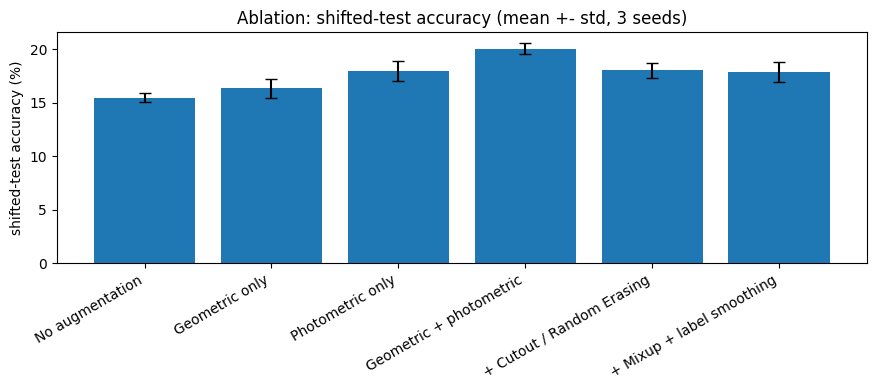

In [57]:
names = list(results.keys())
means = [np.mean(np.array(results[n])[:, 2]) for n in names]
stds = [np.std(np.array(results[n])[:, 2]) for n in names]

plt.figure(figsize=(9, 4))
plt.bar(range(len(names)), means, yerr=stds, capsize=4)
plt.xticks(range(len(names)), names, rotation=30, ha='right')
plt.ylabel('shifted-test accuracy (%)')
plt.title('Ablation: shifted-test accuracy (mean +- std, 3 seeds)')
plt.tight_layout()
plt.show()

In [58]:
for i in range(1, len(means)):
    print('%-28s %+.1f points compared to the row above' % (names[i], means[i] - means[i - 1]))
print('Best gain over baseline:', names[int(np.argmax(means))], '(+%.1f)' % (max(means) - means[0]))

Geometric only               +0.9 points compared to the row above
Photometric only             +1.6 points compared to the row above
Geometric + photometric      +2.0 points compared to the row above
+ Cutout / Random Erasing    -2.0 points compared to the row above
+ Mixup + label smoothing    -0.1 points compared to the row above
Best gain over baseline: Geometric + photometric (+4.6)


## Part E: Error analysis (final model on the shifted test)

In [59]:
final_model = models[best_name]
preds = get_predictions(final_model, shifted_images).argmax(1)
conf_matrix = confusion_matrix(shifted_labels, preds, normalize='true')

In [60]:
print('accuracy per class:')
for i, name in enumerate(class_names):
    print('%-6s %.1f %%' % (name, conf_matrix[i, i] * 100))

accuracy per class:
plane  8.3 %
car    38.3 %
bird   4.0 %
cat    29.5 %
deer   5.7 %
dog    15.3 %
frog   7.2 %
horse  14.4 %
ship   10.6 %
truck  17.4 %


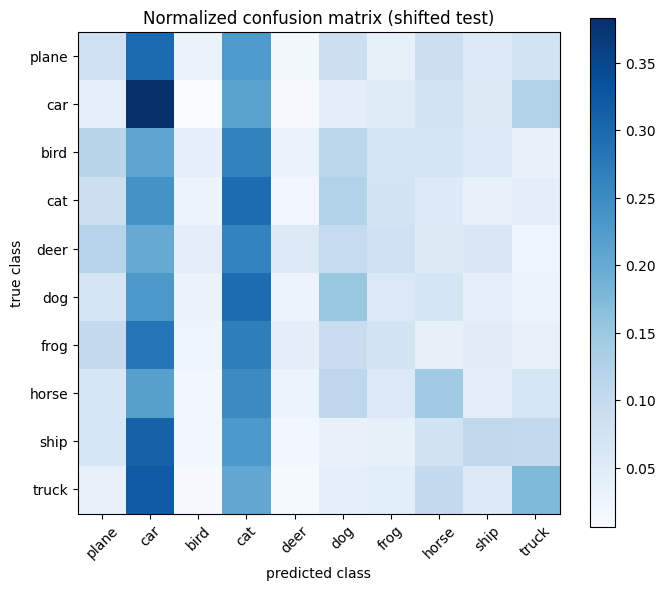

In [61]:
plt.figure(figsize=(7, 6))
plt.imshow(conf_matrix, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.xlabel('predicted class')
plt.ylabel('true class')
plt.title('Normalized confusion matrix (shifted test)')
plt.tight_layout()
plt.show()

In [62]:
# most confused pairs 
errors = conf_matrix.copy()
np.fill_diagonal(errors, 0)
top = np.dstack(np.unravel_index(np.argsort(-errors.ravel())[:5], errors.shape))[0]
for true_c, pred_c in top:
    print('%-6s predicted as %-6s : %.1f %%' % (class_names[true_c], class_names[pred_c], errors[true_c, pred_c] * 100))

truck  predicted as car    : 31.9 %
ship   predicted as car    : 31.0 %
plane  predicted as car    : 29.8 %
dog    predicted as cat    : 29.5 %
frog   predicted as car    : 28.0 %


**Most confused classes:** car/truck,car/ship,cat/dog,cat/frog,cat/frog

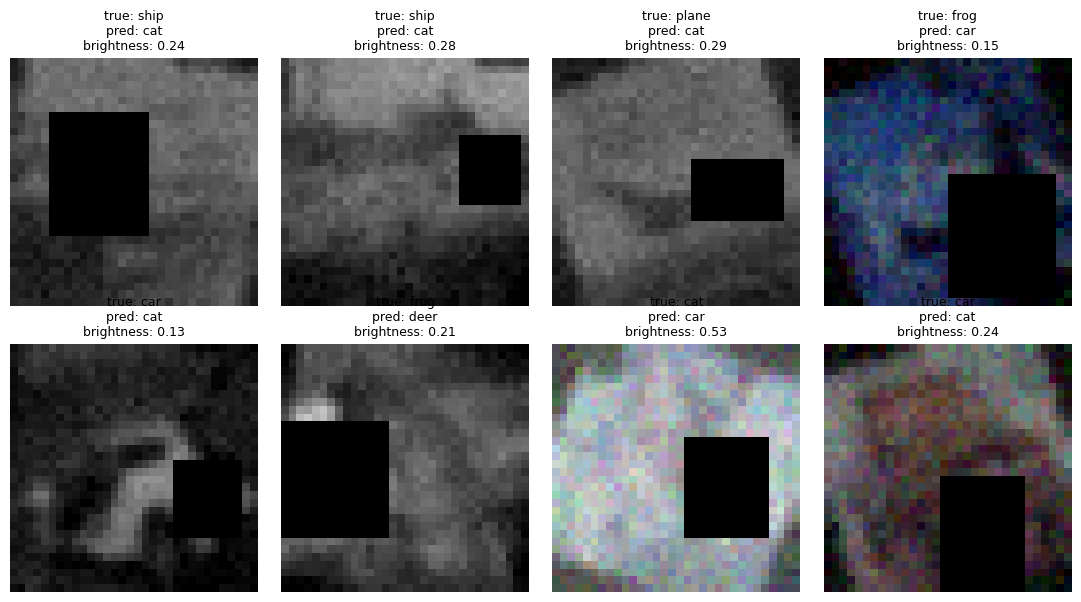

In [63]:
wrong = (preds != shifted_labels).nonzero().flatten()[:8]

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for ax, i in zip(axes.flatten(), wrong):
    ax.imshow(shifted_images[i].permute(1, 2, 0))
    ax.set_title('true: %s\npred: %s\nbrightness: %.2f' % (
        class_names[shifted_labels[i]], class_names[preds[i]], shifted_images[i].mean()), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Why each image failed (write one line per image after you look at the figure).** Things to look for:
image1 due to low brightness,blackbox covering the main region.
image2 due to bluriness and low light.
image3 due to blurriness, and grey scale
image4 due to blackbox covering the head.
image5 due to greyscale,bluriness
image6 due to the blackbox, noise, and no texture showing
image7 due to the rotation,blackbox and noise
image8 due to the low brightness,rotation and no edges

* black box covers the head, wheels or main part of the object
* very dark or low contrast image, object blends with background
* blur or noise removed the texture and edges
* object is tilted by the rotation
* wrong colors (grayscale or swapped channels)
* two similar classes (cat/dog, car/truck)


In [64]:
# hidden corruption that applied to the clean test set
random.seed(7)
hidden_images = torch.stack([hidden_corruption(img) for img in clean_images])

baseline_model = models['No augmentation']
print('final model    : clean %.1f -> hidden only %.1f' % (
    accuracy(final_model, clean_images, clean_labels), accuracy(final_model, hidden_images, clean_labels)))
print('baseline model : clean %.1f -> hidden only %.1f' % (
    accuracy(baseline_model, clean_images, clean_labels), accuracy(baseline_model, hidden_images, clean_labels)))

final model    : clean 45.4 -> hidden only 32.1
baseline model : clean 45.4 -> hidden only 32.1
